# Homework 8 — Matching

## Summary

| Question | Computed result | Closest answer |
|---|---:|---|
| Q1: Inverse probability weighted effect | 2.274341 | **B — 2.3** |
| Q2: First three propensity scores | [0.840114, 0.584646, 0.711082] | **A** |
| Q3: Treated-to-untreated Mahalanobis matching | 3.437679 | **D — 3.4** |
| Q4: Nearest untreated coordinates for weakest-supported treated item | (1.519995, −1.282208) | **D — (1.5, −1.3)** |

## Context & Methods

**Sources:** user-supplied Week 8 coding quiz; `Homework Instructions + Data Files/homework_8.1.csv`; `Homework Instructions + Data Files/homework_8.2.csv`; and Homework Reflection 8 in `Homework Refelction Instructions/Homework-Reflections-5-8`.

### Key assumptions and choices

- Fit sklearn logistic regression with its default L2 regularization (C = 1) and an intercept. Z predicts binary treatment X; use the probability for class 1. Preserve CSV row order for Q2.
- Use normalized, within-group weighted means for Q1 (the Hájek estimator). Also report the unnormalized Horvitz–Thompson estimator as a sensitivity check. Do not trim observations or clip propensity scores: the supplied scores are strictly inside (0,1).
- For Q3, use the covariance of both Z columns over **all** observations and invert it, as requested. Match each treated observation to one untreated observation with replacement using `scipy.spatial.distance.mahalanobis`. Average treated outcome minus matched untreated outcome. This is an ATT-style estimator because only treated observations are averaged; retain the quiz's requested calculation when it calls this ATE.
- Q4 finds the treated observation whose **minimum** untreated distance is largest, then reports its nearest untreated match's Z1 and Z2. Inspect both members of that pair below.
- Causal interpretation requires consistency, no interference, adequate overlap, and no unmeasured confounding given the matching/propensity covariates. These calculations do not by themselves verify those assumptions.

Dependencies: Python 3, numpy, pandas, scipy, scikit-learn, matplotlib and IPython. Run top-to-bottom from the project root or a project subfolder.

In [1]:
from pathlib import Path
import hashlib
import platform
import importlib.metadata
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from scipy.spatial.distance import mahalanobis, cdist
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.precision', 6)
plt.rcParams.update({'figure.figsize': (9,4.8), 'figure.dpi': 110,
                     'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .2, 'axes.axisbelow': True})
BLUE, GOLD, DARK = '#2563EB', '#B7791F', '#374151'

def locate_source(filename):
    for folder in (Path.cwd(), *Path.cwd().parents):
        candidate = folder/'Homework Instructions + Data Files'/filename
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(filename)

frames = {}
for filename, required in [('homework_8.1.csv',['X','Y','Z']),
                           ('homework_8.2.csv',['X','Y','Z1','Z2'])]:
    path = locate_source(filename)
    frame = pd.read_csv(path)
    assert set(required).issubset(frame.columns)
    assert np.isfinite(frame[required].to_numpy(dtype=float)).all()
    assert set(frame.X.unique()) == {0,1}
    frames[filename] = frame
    print(filename, 'rows:',len(frame), 'duplicates:',frame.duplicated().sum())
    print('SHA-256:',hashlib.sha256(path.read_bytes()).hexdigest())
data_ipw = frames['homework_8.1.csv']
data_match = frames['homework_8.2.csv']
display(data_ipw.head(3))
display(data_match.head(3))


homework_8.1.csv rows: 1000 duplicates: 0
SHA-256: 7302004ba3e49cfea57398f7931dfca2b5bf92a99d64cce974769c21404adc5e
homework_8.2.csv rows: 1000 duplicates: 0
SHA-256: 799cf7ef12229d3ca183d1c4f635e4a263f1d03340b75ff360c7f3576944fb2b


,X,Y,Z
0,1,4.109218,1.764052
1,0,2.259504,0.400157
2,0,-0.647584,0.978738


,X,Y,Z1,Z2
0,1,4.652085,1.764052,2.320015
1,1,2.590221,0.400157,1.292631
2,1,3.898981,0.978738,0.556423


## Results

### Question 1 — Inverse probability weighting

**Prompt:** Using `homework_8.1.csv`, find the average treatment effect with inverse probability weighting. Estimate propensity scores by logistic regression with Z predicting X; use weight 1/P for X = 1 and 1/(1−P) for X = 0. Calculate the weighted outcome difference. Include the code and an explanation of choices in the reflection.

**Choices:** A: 2.0 · B: 2.3 · C: 2.6 · D: 2.9

For fitted scores eᵢ, the normalized estimate is Σ(XᵢYᵢ/eᵢ)/Σ(Xᵢ/eᵢ) − Σ((1−Xᵢ)Yᵢ/(1−eᵢ))/Σ((1−Xᵢ)/(1−eᵢ)).

In [2]:
propensity_model = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000)
propensity_model.fit(data_ipw[['Z']], data_ipw.X)
class_one = list(propensity_model.classes_).index(1)
propensity = propensity_model.predict_proba(data_ipw[['Z']])[:,class_one]
assert np.all((propensity > 0) & (propensity < 1))
treated_mask = data_ipw.X.to_numpy() == 1
y = data_ipw.Y.to_numpy()
weights = np.where(treated_mask,1/propensity,1/(1-propensity))
weighted_treated = np.average(y[treated_mask],weights=weights[treated_mask])
weighted_untreated = np.average(y[~treated_mask],weights=weights[~treated_mask])
ipw_ate = weighted_treated-weighted_untreated
ht_ate = np.mean(np.where(treated_mask,y/propensity,-y/(1-propensity)))
ipw_summary = pd.DataFrame({'Estimator':['Unweighted outcome difference','Normalized IPW (quiz answer)',
                                         'Unnormalized Horvitz–Thompson'],
    'Effect':[y[treated_mask].mean()-y[~treated_mask].mean(),ipw_ate,ht_ate]})
display(ipw_summary)
display(pd.DataFrame([{'Group':label,'Rows':int(mask.sum()),
    'Min propensity':propensity[mask].min(),'Max propensity':propensity[mask].max(),
    'Max weight':weights[mask].max(),'Effective sample size':weights[mask].sum()**2/(weights[mask]**2).sum()}
    for label,mask in [('Treated',treated_mask),('Untreated',~treated_mask)]]))
print('Q1: B — 2.3; both IPW conventions select B.')


,Estimator,Effect
0,Unweighted outcome difference,3.036626
1,Normalized IPW (quiz answer),2.274341
2,Unnormalized Horvitz–Thompson,2.239259


,Group,Rows,Min propensity,Max propensity,Max weight,Effective sample size
0,Treated,481,0.094932,0.932157,10.533822,385.208797
1,Untreated,519,0.048043,0.921363,12.716721,389.212008


Q1: B — 2.3; both IPW conventions select B.


### Question 2 — First three propensity scores

**Prompt:** The propensity scores of the first three items in the dataframe are closest to:

**Choices:** A: [0.84, 0.58, 0.71] · B: [0.28, 0.34, 0.92] · C: [0.08, 0.65, 0.38] · D: [0.74, 0.39, 0.52]

**Answer: A.** These are the first three original CSV rows, without sorting or splitting the data.

,X,Y,Z,propensity
0,1,4.109218,1.764052,0.840114
1,0,2.259504,0.400157,0.584646
2,0,-0.647584,0.978738,0.711082


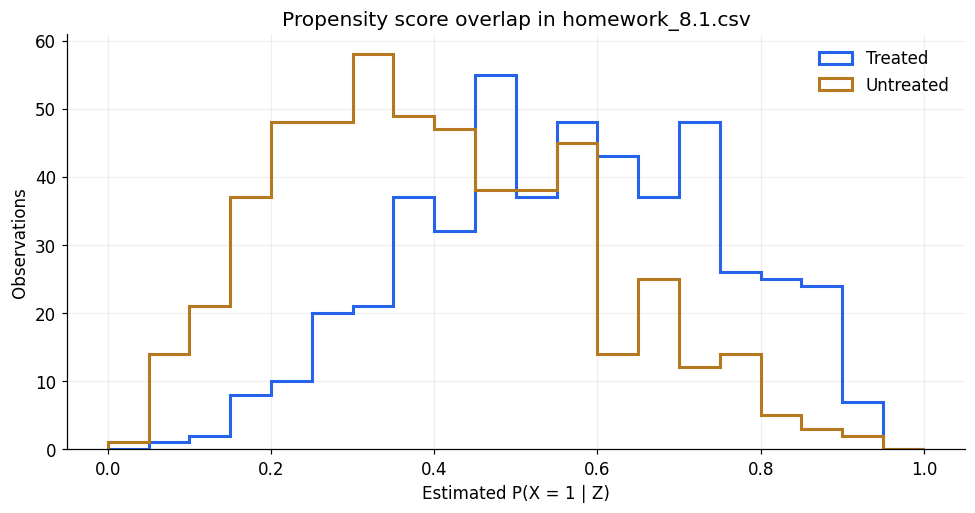

In [3]:
display(data_ipw.head(3).assign(propensity=propensity[:3]))
score_choices = {'A':[.84,.58,.71],'B':[.28,.34,.92],
                 'C':[.08,.65,.38],'D':[.74,.39,.52]}
assert min(score_choices,key=lambda k:np.linalg.norm(propensity[:3]-score_choices[k])) == 'A'
fig, ax = plt.subplots()
for mask,color,label in [(treated_mask,BLUE,'Treated'),(~treated_mask,GOLD,'Untreated')]:
    ax.hist(propensity[mask],bins=np.linspace(0,1,21),histtype='step',linewidth=2,color=color,label=label)
ax.set(title='Propensity score overlap in homework_8.1.csv',xlabel='Estimated P(X = 1 | Z)',ylabel='Observations')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


### Question 3 — Mahalanobis nearest matching with replacement

**Prompt:** Using `homework_8.2.csv`, match all treated items to the single nearest untreated item using Mahalanobis distance, with replacement. Use SciPy's `mahalanobis` function. Make the Z1 and Z2 values into a 2 × N matrix, compute its 2 × 2 covariance, and invert it. The resulting effect is closest to:

**Choices:** A: 2.5 · B: 2.8 · C: 3.1 · D: 3.4

**Answer: D — 3.4.** The required treated-to-untreated average is 3.437679. Reusing controls is allowed; no one-to-one assignment, standardization, trimming, or reverse-direction matching is imposed.

In [4]:
covariate_matrix = data_match[['Z1','Z2']].to_numpy().T  # 2 × N, all observations
covariance = np.cov(covariate_matrix, ddof=1)
assert covariance.shape == (2,2)
assert np.linalg.eigvalsh(covariance).min() > 0
inverse_covariance = np.linalg.inv(covariance)
treated = data_match.loc[data_match.X == 1].copy()
untreated = data_match.loc[data_match.X == 0].copy()
zt,zu = treated[['Z1','Z2']].to_numpy(),untreated[['Z1','Z2']].to_numpy()
distances = np.array([[mahalanobis(t,u,inverse_covariance) for u in zu] for t in zt])
nearest_positions = distances.argmin(axis=1)
nearest_distances = distances[np.arange(len(treated)),nearest_positions]
matched = untreated.iloc[nearest_positions]
effects = treated.Y.to_numpy()-matched.Y.to_numpy()
matching_effect = effects.mean()
pairs = pd.DataFrame({'treated_row':treated.index.to_numpy(),
    'untreated_row':matched.index.to_numpy(),'distance':nearest_distances,
    'treated_Y':treated.Y.to_numpy(),'untreated_Y':matched.Y.to_numpy(),
    'effect':effects})
display(pd.DataFrame(covariance,index=['Z1','Z2'],columns=['Z1','Z2']))
display(pairs.head())
print('Treated observations:',len(treated),'Untreated observations:',len(untreated))
print('Unique untreated matches:',np.unique(nearest_positions).size)
print('Mean treated-minus-match effect:',matching_effect)
# A vectorized SciPy implementation independently verifies every distance and match.
np.testing.assert_allclose(distances,cdist(zt,zu,metric='mahalanobis',VI=inverse_covariance))


,Z1,Z2
Z1,0.97521,0.945070
Z2,0.94507,1.853202


,treated_row,untreated_row,distance,treated_Y,untreated_Y,effect
0,0,681,0.648812,4.652085,0.428954,4.223131
1,1,752,0.066003,2.590221,-0.034844,2.625065
2,2,892,0.082207,3.898981,1.164988,2.733993
3,3,922,0.974003,5.857179,1.797450,4.059729
4,4,922,0.687321,3.647489,1.797450,1.850039


Treated observations: 483 Untreated observations: 517
Unique untreated matches: 172
Mean treated-minus-match effect: 3.437678997911326


### Question 4 — Least common support

**Prompt:** Find the nearest Z1 and Z2 values of the treated item with the least common support (the farthest Mahalanobis distance from the untreated).

**Choices:** A: (2.3, 1.2) · B: (0.2, −0.4) · C: (0.9, 1.4) · D: (1.5, −1.3)

**Answer: D — (1.5, −1.3).** First minimize the distance to untreated observations for every treated observation; then maximize those minima. Report the covariates of the selected treated observation's nearest untreated match. Both rows and the distance are shown below to make this interpretation explicit.

,X,Y,Z1,Z2
Weakest-supported treated,1.0,6.540236,2.696224,0.538155
Nearest untreated,0.0,5.407995,1.519995,-1.282208


Original zero-based treated row: 494
Original zero-based untreated row: 418
Mahalanobis distance: 1.383004533035377


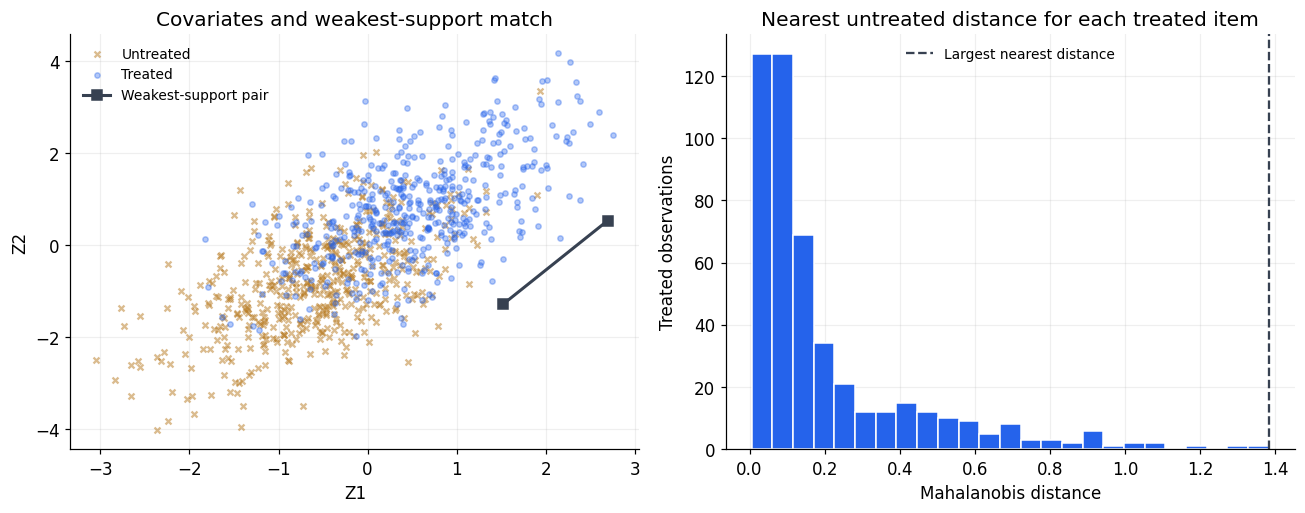

In [5]:
weakest_position = nearest_distances.argmax()
weakest_treated = treated.iloc[weakest_position]
nearest_untreated = untreated.iloc[nearest_positions[weakest_position]]
weakest_pair = pd.DataFrame([weakest_treated,nearest_untreated],index=['Weakest-supported treated','Nearest untreated'])
display(weakest_pair)
print('Original zero-based treated row:',treated.index[weakest_position])
print('Original zero-based untreated row:',untreated.index[nearest_positions[weakest_position]])
print('Mahalanobis distance:',nearest_distances[weakest_position])
q4_coords = nearest_untreated[['Z1','Z2']].to_numpy(dtype=float)
q4_options = {'A':[2.3,1.2],'B':[.2,-.4],'C':[.9,1.4],'D':[1.5,-1.3]}
assert min(q4_options,key=lambda k:np.linalg.norm(q4_coords-q4_options[k])) == 'D'
fig,axes = plt.subplots(1,2,figsize=(12,4.8))
axes[0].scatter(zu[:,0],zu[:,1],s=15,color=GOLD,marker='x',alpha=.5,label='Untreated')
axes[0].scatter(zt[:,0],zt[:,1],s=12,color=BLUE,alpha=.35,label='Treated')
axes[0].plot([weakest_treated.Z1,nearest_untreated.Z1],[weakest_treated.Z2,nearest_untreated.Z2],
             color=DARK,linewidth=2,marker='s',label='Weakest-support pair')
axes[0].set(title='Covariates and weakest-support match',xlabel='Z1',ylabel='Z2')
axes[0].legend(frameon=False,fontsize=9)
axes[1].hist(nearest_distances,bins=25,color=BLUE,edgecolor='white')
axes[1].axvline(nearest_distances.max(),color=DARK,linestyle='--',label='Largest nearest distance')
axes[1].set(title='Nearest untreated distance for each treated item',xlabel='Mahalanobis distance',ylabel='Treated observations')
axes[1].legend(frameon=False,fontsize=9)
fig.tight_layout()
plt.show()


## Homework Reflection 8

The next cell creates the three-paragraph reflection directly from the calculated results. The code throughout this notebook is the quiz solution and is copied into the separate reflection file.

In [6]:
reflection8 = f"""# Homework Reflection 8 — Matching

For inverse probability weighting, I fit an intercept and logistic regression of X on Z using sklearn's default L2 regularization (C = 1), then select the predicted probability of class 1. I keep the original row order, giving first-three propensity scores **{np.round(propensity[:3],6).tolist()}** (Q2 **A**). I assign treated weights 1/p and untreated weights 1/(1−p), then subtract the normalized weighted untreated mean of Y from the normalized weighted treated mean. The estimated effect is **{ipw_ate:.6f}**, so Q1 is **B — 2.3**. Choosing a normalization is an implementation issue: the alternative unnormalized Horvitz–Thompson estimate is **{ht_ate:.6f}**, which selects the same option. I check probabilities and weight sizes rather than silently clipping scores or dropping observations; small scores in the treated group or large scores in the untreated group can create influential weights.

For Mahalanobis matching, I stack all Z1 and Z2 values into a 2 × N matrix, compute its sample covariance, and invert that matrix. I explicitly call scipy.spatial.distance.mahalanobis on every treated–untreated pair, choose each treated item's nearest untreated item, and permit repeated use of the same control. Averaging treated Y minus matched untreated Y gives **{matching_effect:.6f}**, so Q3 is **D — 3.4**. The main implementation challenges are orienting the covariance matrix correctly, using all observations for covariance as instructed, and preserving positions and original row identifiers after splitting the groups. I independently check every distance with SciPy's vectorized cdist. Although the quiz calls this ATE, averaging only over treated items has an ATT interpretation.

For common support, I first find each treated item's minimum distance to the untreated group, then select the largest of those minima. The weakest-supported treated item is original row **{treated.index[weakest_position]}**, with covariates **({weakest_treated.Z1:.6f}, {weakest_treated.Z2:.6f})**. Its nearest untreated match is original row **{untreated.index[nearest_positions[weakest_position]]}**, with covariates **({q4_coords[0]:.6f}, {q4_coords[1]:.6f})** and distance **{nearest_distances.max():.6f}**, selecting Q4 **D — (1.5, −1.3)**. The key distinction is between the weakest-supported treated observation and the nearest untreated coordinates requested in the choices. Matching always finds a nearest available observation, but that alone does not guarantee a close or credible counterfactual; the distance plot exposes the weak-support tail.
"""
display(Markdown(reflection8))


# Homework Reflection 8 — Matching

For inverse probability weighting, I fit an intercept and logistic regression of X on Z using sklearn's default L2 regularization (C = 1), then select the predicted probability of class 1. I keep the original row order, giving first-three propensity scores **[0.840114, 0.584646, 0.711082]** (Q2 **A**). I assign treated weights 1/p and untreated weights 1/(1−p), then subtract the normalized weighted untreated mean of Y from the normalized weighted treated mean. The estimated effect is **2.274341**, so Q1 is **B — 2.3**. Choosing a normalization is an implementation issue: the alternative unnormalized Horvitz–Thompson estimate is **2.239259**, which selects the same option. I check probabilities and weight sizes rather than silently clipping scores or dropping observations; small scores in the treated group or large scores in the untreated group can create influential weights.

For Mahalanobis matching, I stack all Z1 and Z2 values into a 2 × N matrix, compute its sample covariance, and invert that matrix. I explicitly call scipy.spatial.distance.mahalanobis on every treated–untreated pair, choose each treated item's nearest untreated item, and permit repeated use of the same control. Averaging treated Y minus matched untreated Y gives **3.437679**, so Q3 is **D — 3.4**. The main implementation challenges are orienting the covariance matrix correctly, using all observations for covariance as instructed, and preserving positions and original row identifiers after splitting the groups. I independently check every distance with SciPy's vectorized cdist. Although the quiz calls this ATE, averaging only over treated items has an ATT interpretation.

For common support, I first find each treated item's minimum distance to the untreated group, then select the largest of those minima. The weakest-supported treated item is original row **494**, with covariates **(2.696224, 0.538155)**. Its nearest untreated match is original row **418**, with covariates **(1.519995, -1.282208)** and distance **1.383005**, selecting Q4 **D — (1.5, −1.3)**. The key distinction is between the weakest-supported treated observation and the nearest untreated coordinates requested in the choices. Matching always finds a nearest available observation, but that alone does not guarantee a close or credible counterfactual; the distance plot exposes the weak-support tail.


## Checks and reproducibility

Input checksums, estimator choices and matching conventions are recorded above. All results are deterministic. The independent distance comparison verifies the full pairwise matrix, and the option checks verify score and coordinate interpretation. The reflection contains three prose paragraphs, as required.

In [7]:
quiz_answers = pd.DataFrame({'Question':['Q1','Q2','Q3','Q4'],
                              'Answer':['B — 2.3','A — [0.84, 0.58, 0.71]','D — 3.4','D — (1.5, −1.3)']})
display(quiz_answers)
assert min({'A':2.,'B':2.3,'C':2.6,'D':2.9},key=lambda k:abs({'A':2.,'B':2.3,'C':2.6,'D':2.9}[k]-ipw_ate))=='B'
assert min({'A':2.5,'B':2.8,'C':3.1,'D':3.4},key=lambda k:abs({'A':2.5,'B':2.8,'C':3.1,'D':3.4}[k]-matching_effect))=='D'
print('Python:',platform.python_version())
for package in ['numpy','pandas','scipy','scikit-learn','matplotlib']:
    print(package,importlib.metadata.version(package))


,Question,Answer
0,Q1,B — 2.3
1,Q2,"A — [0.84, 0.58, 0.71]"
2,Q3,D — 3.4
3,Q4,"D — (1.5, −1.3)"


Python: 3.13.5
numpy 2.4.1
pandas 3.0.0
scipy 1.17.0
scikit-learn 1.8.0
matplotlib 3.10.8


### Presentation check

All cells executed top-to-bottom, notebook structure validated, and the saved figure images were visually inspected. A full HTML page preview could not be inspected because no browser was available. To render a local preview, run `python3 -m jupyter nbconvert --to html homework_8_matching.ipynb` from this notebook's folder, then open the resulting HTML file in a browser.